# Physics-consistency figures

Same infrastructure as `figures.ipynb`: shared `MODEL_REGISTRY` (colors, labels,
line styles, legend grouping), multi-PDE auto-discovery of `*_metrics.csv`
files (seeds parsed from filenames / the `seed` column), LaTeX fonts.

**Seed convention used throughout**
- *seed-resolved* plots: one line per seed, drawn in progressively lighter
  **shades of the model's registry color**;
- *seed-averaged* plots: trajectories are averaged **within** each seed first,
  then the line is the mean across seeds in the **main registry color**, with a
  $\pm 1$ sd band across seeds (models with a single seed get a line, no band).

Adding a PDE later = drop its `*_metrics.csv` files into
`experiments/<pde>/metrics/` and (if new) add the PDE to `PDEs`,
`PDE_LABELS`, `pde_xlims`, `horizon_fn`, `DATASET_METRIC`. Nothing else.

In [33]:
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns          # only for optional exploration; NEVER call
import pandas as pd            # sns.set_theme() here — it clobbers the LaTeX rc
import numpy as np
import shutil
import glob
import math
import sys
import re

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": shutil.which("latex") is not None,   # same LaTeX font as figures.ipynb
    "text.latex.preamble": r"\usepackage{amsfonts}",
}
plt.rcParams.update(rc)

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

FIG_DIR   = Path(PROJECT_ROOT) / "figures"
SAVE_FIGS = False
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Model Registry — identical to `figures.ipynb`

Copy of the registry so colors/labels/line styles match every other figure. `FourierFlow_16modes_v4.0` added (it was referenced in the old physics notebook but missing from the registry).

In [34]:
def rgb_to_hex(r, g, b):
    return f"#{r:02x}{g:02x}{b:02x}"

MODEL_REGISTRY = {
    "WaveletFlow_1scale_haar_v4.0": dict(
        label  = "WFM 1-scale haar (ours)",
        color  = rgb_to_hex(55, 82, 64),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 1-scale (ours)", legend_rank = 0,
    ),
    "WaveletFlow_1scale_db2_v4.0": dict(
        label  = "WFM 1-scale db2 (ours)",
        color  = rgb_to_hex(55, 82, 64),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 1-scale (ours)", legend_rank = 0,
    ),
    "WaveletFlow_1scale_db4_v4.0": dict(
        label  = "WFM 1-scale db4 (ours)",
        color  = rgb_to_hex(55, 82, 64),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 1-scale (ours)", legend_rank = 0,
    ),
    "WaveletFlow_1scale_db6_v4.0": dict(
        label  = "WFM 1-scale db6 (ours)",
        color  = rgb_to_hex(55, 82, 64),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 1-scale (ours)", legend_rank = 0,
    ),
    "WaveletFlow_3scales_haar_v4.0": dict(
        label  = "WFM 3-scale haar (ours)",
        color  = rgb_to_hex(117, 176, 138),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 3-scale (ours)", legend_rank = 1,
    ),
    "WaveletFlow_3scales_db2_v4.0": dict(
        label  = "WFM 3-scale db2 (ours)",
        color  = rgb_to_hex(117, 176, 138),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 3-scale (ours)", legend_rank = 1,
    ),
    "WaveletFlow_3scales_db4_v4.0": dict(
        label  = "WFM 3-scale db4 (ours)",
        color  = rgb_to_hex(117, 176, 138),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 3-scale (ours)", legend_rank = 1,
    ),
    "WaveletFlow_3scales_db6_v4.0": dict(
        label  = "WFM 3-scale db6 (ours)",
        color  = rgb_to_hex(117, 176, 138),
        dash   = (1, 0), lw = 2.5,
        groups = {"ours"},
        legend_group = "WFM 3-scale (ours)", legend_rank = 1,
    ),
    "FM_data_space_v4.0": dict(
        label  = r"FM$_{pixel}$",
        color  = rgb_to_hex(176, 176, 176),
        dash   = (1, 0), lw = 1.8,
        groups = {"generative"}, legend_rank = -1,
    ),
    #"FourierFlow_32modes_v4.0": dict(
    #    label  = r"FM$_{fourier}$",
    #    color  = rgb_to_hex(143, 94, 106),
    #    dash   = (1, 0), lw = 1.8,
    #    groups = {"generative"}, legend_rank = 3,
    #),
    "FourierFlow_16modes_v4.0": dict(                   # ← added: used by the
        label  = r"FM$_{fourier}$",                     #   physics CSVs
        color  = rgb_to_hex(171, 122, 134),
        dash   = (1, 0), lw = 1.8,
        groups = {"generative"}, legend_rank = 3,
    ),
    "WDNO": dict(
        label  = "WDNO",
        color  = rgb_to_hex(191, 134, 148),
        dash   = (1, 0), lw = 1.8,
        groups = {"generative"}, legend_rank = 4,
    ),
    "WNO_3scales_db2": dict(
        label  = "WNO",
        color  = rgb_to_hex(176, 136, 84),
        dash   = (1, 0), lw = 1.8,
        groups = {"deterministic"}, legend_rank = 5,
    ),
    "FNO": dict(
        label  = "FNO",
        color  = rgb_to_hex(208, 169, 110),
        dash   = (1, 0), lw = 1.8,
        groups = {"deterministic"}, legend_rank = 6,
    ),
    "TFNO": dict(
        label  = "TFNO",
        color  = rgb_to_hex(236, 227, 163),
        dash   = (1, 0), lw = 1.8,
        groups = {"deterministic"}, legend_rank = 7,
    ),
}

PDEs = ['turbulent_radiative_layer_2D', 'rayleigh_benard', 'active_matter']

# which WFM wavelet wins per PDE (same as figures.ipynb)
pde_best_model = {
    "turbulent_radiative_layer_2D": ["WaveletFlow_1scale_haar_v4.0", "WaveletFlow_3scales_haar_v4.0"],
    "rayleigh_benard":              ["WaveletFlow_1scale_db4_v4.0", "WaveletFlow_3scales_db4_v4.0"],
    "active_matter":                ["WaveletFlow_1scale_haar_v4.0", "WaveletFlow_3scales_db2_v4.0"],
}

model_checklist = [m for m in MODEL_REGISTRY]

palette     = {m: MODEL_REGISTRY[m]["color"] for m in model_checklist}
dashes      = {m: MODEL_REGISTRY[m]["dash"]  for m in model_checklist}
labels      = {m: MODEL_REGISTRY[m]["label"] for m in model_checklist}
linewidths  = {m: MODEL_REGISTRY[m]["lw"]    for m in model_checklist}

det_models  = [m for m in model_checklist if "deterministic" in MODEL_REGISTRY[m]["groups"]]
gen_models  = [m for m in model_checklist if "generative"    in MODEL_REGISTRY[m]["groups"]]
ours_models = [m for m in model_checklist if "ours"          in MODEL_REGISTRY[m]["groups"]]

color_to_model = {v: k for k, v in palette.items()}

GT_LABEL             = "Ground-truth"
palette[GT_LABEL]    = "#222222"
dashes[GT_LABEL]     = (4, 2)
labels[GT_LABEL]     = "Ground-truth"
linewidths[GT_LABEL] = 1.8

def model_type(model):
    groups = MODEL_REGISTRY.get(model, {}).get("groups", set())
    if "ours"       in groups: return "ours"
    if "generative" in groups: return "generative"
    return "deterministic"

def legend_order(model_subset):
    registry_keys = list(MODEL_REGISTRY.keys())
    def rank(m):
        return (MODEL_REGISTRY[m].get("legend_rank", 999),
                registry_keys.index(m) if m in registry_keys else 999)
    return sorted(model_subset, key=rank)

# Load metrics files

Auto-discovers every `*_metrics.csv` under `experiments/<pde>/metrics/` for each registry model, across all seeds. Seed comes from the CSV's `seed` column (stamped by `inference.py`), with a filename-regex fallback. `_global_` rows carry the coupled diagnostics; the rest are per-field.

In [35]:
GLOBAL_FIELD_LABEL = "_global_"
METRICS_SUBDIR     = "metrics"          # change to "results" if reading in place
SEED_RE            = re.compile(r"seed(\d+)")

def enrich_metrics(df, stem, model_name, pde):
    parts     = stem.split('_')
    nsampling = next((p.replace('nsampling', '') for p in parts if p.startswith('nsampling')), None)
    nens      = next((p.replace('nens',      '') for p in parts if p.startswith('nens')),      None)
    df['model'] = model_name                       # force registry key
    if 'seed' not in df.columns or df['seed'].isna().all():
        m = SEED_RE.search(stem)
        df['seed'] = int(m.group(1)) if m else -1
    df['seed']      = df['seed'].astype(int)
    df['source']    = stem
    df['pde']       = pde
    df['nsampling'] = int(nsampling) if nsampling else None
    df['nens']      = int(nens)      if nens      else None
    return df

dfs_metrics = []
for pde in PDEs:
    print(f"\n{'='*60}\nLoading PDE: {pde}\n{'='*60}")
    for model in model_checklist:
        pattern = f'{PROJECT_ROOT}/experiments/{pde}/{METRICS_SUBDIR}/{model}_nsampling*_metrics.csv'
        files   = sorted(glob.glob(pattern))
        if not files:
            print(f"  [    ] no metrics for '{model}'")
            continue
        for fpath in files:
            try:
                d    = pd.read_csv(fpath)
                stem = Path(fpath).stem
                d    = enrich_metrics(d, stem, model, pde)
                dfs_metrics.append(d)
                print(f"  [OK  ] {d.shape} seed={d['seed'].iloc[0]:<4d} | {Path(fpath).name}")
            except Exception as e:
                print(f"  [ERR ] {fpath}: {e}")

DEDUP_EXCLUDE = {'source', 'nsampling', 'nens'}
if dfs_metrics:
    metrics_df = pd.concat(dfs_metrics, ignore_index=True)
    metrics_df = metrics_df.drop_duplicates(
        subset=[c for c in metrics_df.columns if c not in DEDUP_EXCLUDE])
else:
    metrics_df = pd.DataFrame()
    print("[WARN] no metrics loaded")

pde_present = [p for p in PDEs if not metrics_df.empty and p in set(metrics_df['pde'])]
print(f"\nmetrics_df: {metrics_df.shape} | PDEs present: {pde_present}")
if not metrics_df.empty:
    print(metrics_df.groupby(['pde','model'])['seed']
          .unique().apply(sorted).rename('seeds').to_string())


Loading PDE: turbulent_radiative_layer_2D
  [OK  ] (4365, 65) seed=168  | WaveletFlow_1scale_haar_v4.0_nsampling50_nens8_seed168_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 65) seed=42   | WaveletFlow_1scale_haar_v4.0_nsampling50_nens8_seed42_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 65) seed=84   | WaveletFlow_1scale_haar_v4.0_nsampling50_nens8_seed84_turbulent_radiative_layer_2D_metrics.csv
  [    ] no metrics for 'WaveletFlow_1scale_db2_v4.0'
  [    ] no metrics for 'WaveletFlow_1scale_db4_v4.0'
  [    ] no metrics for 'WaveletFlow_1scale_db6_v4.0'
  [OK  ] (4365, 65) seed=168  | WaveletFlow_3scales_haar_v4.0_nsampling50_nens8_seed168_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 65) seed=42   | WaveletFlow_3scales_haar_v4.0_nsampling50_nens8_seed42_turbulent_radiative_layer_2D_metrics.csv
  [OK  ] (4365, 65) seed=84   | WaveletFlow_3scales_haar_v4.0_nsampling50_nens8_seed84_turbulent_radiative_layer_2D_metrics.csv
  [    ] no metrics for 'Wav

# Config: PDE labels, axis limits, horizons, metric resolution

`horizon_fn` mirrors `figures.ipynb`. `conservation_col` resolves the constraint-residual column per PDE (`continuity_ratio` for compressible TRL, `divnorm_ratio` for incompressible RB/AM). `DATASET_METRIC` maps each PDE to its system-specific scientific observable.

In [36]:
PDE_LABELS = {
    'turbulent_radiative_layer_2D' : 'Turbulent Radiative Layer 2D',
    'rayleigh_benard'              : 'Rayleigh-B\'enard' if rc["text.usetex"] else 'Rayleigh-Bénard',
    'active_matter'                : 'Active Matter',
}

pde_xlims = {
    'turbulent_radiative_layer_2D' : (-5, 100),
    'rayleigh_benard'              : (-5, 200),
    'active_matter'                : (-5, 80),
}

def horizon_rayleigh_benard(t):
    return "01:32" if t < 32 else ("33:64" if t < 64 else "65:196")
def horizon_active_matter(t):
    return "01:16" if t < 16 else ("17:32" if t < 32 else "33:77")
def horizon_turbulent_radiative_layer_2D(t):
    return "01:32" if t < 32 else ("33:64" if t < 64 else "65:97")

horizon_fn = {
    'turbulent_radiative_layer_2D': horizon_turbulent_radiative_layer_2D,
    'rayleigh_benard':              horizon_rayleigh_benard,
    'active_matter':                horizon_active_matter,
}

aggregate_mode = "mean"
def aggregate(x):
    return np.nanmean(x) if "mean" in aggregate_mode else np.nanmedian(x)

if not metrics_df.empty:
    metrics_df['step'] = metrics_df['step'] + 1          # 1-based, as in figures.ipynb
    metrics_df["horizon"] = pd.Series(pd.NA, index=metrics_df.index, dtype="object")
    for pde, fn in horizon_fn.items():
        mask = metrics_df["pde"] == pde
        metrics_df.loc[mask, "horizon"] = metrics_df.loc[mask, "step"].apply(fn)
    metrics_df["model_type"] = metrics_df["model"].apply(model_type)

    g  = metrics_df[metrics_df["field"] == GLOBAL_FIELD_LABEL].copy()
    pf = metrics_df[metrics_df["field"] != GLOBAL_FIELD_LABEL].copy()
else:
    g = pf = pd.DataFrame()

# ── column resolvers (robust to per-PDE differences) ─────────────────────────
CONS_CANDIDATES = ["continuity_ratio", "divnorm_ratio"]

def conservation_col(pde):
    sub = g[g["pde"] == pde]
    for c in CONS_CANDIDATES:
        if c in sub.columns and sub[c].notna().any():
            return c
    return None

DATASET_METRIC = {          # (column, LaTeX label) — the system-specific observable
    'turbulent_radiative_layer_2D': ("massflux_bias", r"$\langle \rho u_y \rangle$ rel.\ bias"),
    'rayleigh_benard':              ("nusselt_bias",  r"$\mathrm{Nu}$ rel.\ bias"),
    'active_matter':                ("nematic_bias",  r"$S$ rel.\ bias"),
}

def models_in(pde, frame=None):
    frame = g if frame is None else frame
    present = set(frame.loc[frame["pde"] == pde, "model"])
    return [m for m in model_checklist if m in present]

TEXT_WIDTH = 12.0
ROW_HEIGHT = 2.8
LEGEND_LW  = 1.8

# Helpers: seed shading, seed-aware aggregation, panels, shared legend

`draw_metric(..., mode="seed_avg")` averages trajectories **within** each seed, then draws the across-seed mean in the model's main color with a $\pm 1$ sd band. `mode="per_seed"` draws one line per seed in lighter shades of the same color (darkest = lowest seed).

In [37]:
def lighten(color, frac):
    """Blend a color toward white; frac=0 -> original, frac=1 -> white."""
    rgb = np.array(mcolors.to_rgb(color))
    return tuple(rgb + (1.0 - rgb) * frac)

def seed_shade_map(model, seeds, max_lighten=0.55):
    seeds = sorted(int(s) for s in set(seeds))
    fracs = np.linspace(0.0, max_lighten, len(seeds)) if len(seeds) > 1 else [0.0]
    return {s: lighten(palette[model], f) for s, f in zip(seeds, fracs)}

def seed_mean(df, metric, extra=()):
    """One value per (pde, model, seed, step[, extra]): mean over trajectories.
    Averaging trajectories first keeps seeds as the replication unit."""
    keys = ["pde", "model", "seed", "step", *extra]
    return (df.dropna(subset=[metric])
              .groupby(keys, as_index=False)[metric].mean())

def draw_metric(ax, df, pde, metric, models_shown, mode="seed_avg",
                logy=False, ref=None, band_alpha=0.18):
    """Draw one metric-vs-lead-time panel with registry styling."""
    if metric not in df.columns:
        ax.set_visible(False); return
    sc = seed_mean(df[df["pde"] == pde], metric)
    for m in models_shown:
        sub = sc[sc["model"] == m]
        if sub.empty:
            continue
        if mode == "per_seed":
            smap = seed_shade_map(m, sub["seed"].unique())
            for s, ss in sub.groupby("seed"):
                ax.plot(ss["step"], ss[metric], color=smap[int(s)],
                        dashes=dashes[m], lw=max(linewidths[m] - 0.7, 0.9),
                        alpha=0.95, zorder=3)
        else:  # seed_avg
            agg = (sub.groupby("step")[metric]
                      .agg(mean="mean", sd="std", n="count").reset_index())
            ax.plot(agg["step"], agg["mean"], color=palette[m],
                    dashes=dashes[m], lw=linewidths[m], zorder=3)
            multi = agg["n"] > 1
            if multi.any():
                a = agg[multi]
                ax.fill_between(a["step"], a["mean"] - a["sd"], a["mean"] + a["sd"],
                                color=palette[m], alpha=band_alpha, lw=0, zorder=2)
    if ref is not None:
        ax.axhline(ref, color="#222222", ls="--", lw=1.0, zorder=1)
    if logy:
        ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.tick_params(direction="in", which="both", labelsize=12)
    ax.set_xlim(*pde_xlims.get(pde, (None, None)))

def registry_handles(models_shown, lw_boost=True):
    """Deduplicated (by legend_group), rank-ordered legend handles."""
    seen, handles, lbls = set(), [], []
    for m in legend_order([m for m in models_shown if m in MODEL_REGISTRY]):
        gkey = MODEL_REGISTRY[m].get("legend_group", m)
        if gkey in seen:
            continue
        seen.add(gkey)
        lw = max(linewidths[m], LEGEND_LW) if lw_boost else linewidths[m]
        handles.append(Line2D([], [], color=palette[m], lw=lw, dashes=dashes[m]))
        lbls.append(MODEL_REGISTRY[m].get("legend_group") or labels.get(m, m))
    return handles, lbls

def add_legend(fig, models_shown, ncol=4, y=-0.02, extra=()):
    handles, lbls = registry_handles(models_shown)
    for h, l in extra:
        handles.append(h); lbls.append(l)
    fig.legend(handles, lbls, loc="lower center", ncol=ncol,
               bbox_to_anchor=(0.5, y), frameon=False, fontsize=11)

def panel_models(pde, restrict_ours_to_best=True):
    """Models present for this PDE; optionally keep only the best 'ours'."""
    ms = models_in(pde)
    if restrict_ours_to_best and pde_best_model.get(pde):
        best = set(pde_best_model[pde])
        ms   = [m for m in ms if m not in ours_models or m in best]
    return ms

# The physics metrics: definitions, formulas, interpretation

All quantities below are computed **per ensemble member first**, then reduced —
the nonlinear functional $Q(\cdot)$ is never applied to the ensemble-mean field
(which would destroy exactly the small-scale structure these metrics measure).
For a diagnostic $Q$, ground truth $x$, and members $x_m$, $m=1..M$, at every
(trajectory, lead time):

$$
\mathrm{bias}_Q=\frac{\left|\frac{1}{M}\sum_m Q(x_m)-Q(x)\right|}{|Q(x)|},
\qquad
\mathrm{mae}_Q=\frac{\frac{1}{M}\sum_m\left|Q(x_m)-Q(x)\right|}{|Q(x)|}.
$$

**Why the pair matters.** These systems are chaotic: members decorrelate from
the truth, so $\mathrm{mae}$ grows for *any* emulator — its growth is not a
defect. $\mathrm{bias}$ measures the *systematic* drift of the whole ensemble.
The healthy signature of a generative emulator is **mae growing while bias
stays flat and small** ("right attractor, different phase"); both growing
together means the model leaves the attractor ("wrong attractor") — the actual
failure mode.

### Cross-system metrics (defined for every PDE → the multi-PDE panels)

**Kinetic energy** — 0th spectral moment; the domain-integrated energy budget:
$$E_k=\tfrac{1}{2}\big\langle u_x^2+u_y^2\big\rangle .$$
*Good:* `ke_pred` tracks `ke_true` within a few \%, flat bias. *Failure
directions:* monotone decay = artificial dissipation (over-smoothing,
typical of pointwise-loss models and deterministic sampling); monotone growth
= energy injection (over-stochastic sampling, precursor of blow-up).

**Enstrophy** — 2nd spectral moment, $\;\mathcal{Z}=\tfrac12\langle\omega^2\rangle$,
$\;\omega=\partial_x u_y-\partial_y u_x$; equivalently $\int k^2E(k)\,dk$, so it
is dominated by small scales. A model can hold $E_k$ while shedding fine-scale
vorticity; enstrophy exposes this, typically diverging much earlier than $E_k$.
This is the metric most directly tied to WFM's per-scale loss normalisation:
retaining enstrophy is the *designed* consequence of weighting detail sub-bands.

**Conservation ratio** — discrete residual of the governing constraint,
normalised by the reference solver's own residual (the stored data does not
satisfy it exactly either). Compressible TRL uses continuity,
$$\mathcal{R}=\frac{\|\partial_t\rho+\nabla\!\cdot\!(\rho u)\|_2^{\;\mathrm{model}}}
{\|\partial_t\rho+\nabla\!\cdot\!(\rho u)\|_2^{\;\mathrm{solver}}},$$
incompressible RB / AM use $\|\nabla\!\cdot\!u\|_2$ in the same ratio.
*Good:* $\mathcal{R}\approx 1$, flat in lead time — the emulator violates the
constraint no worse than the solver's discretisation. $\mathcal{R}\gg 1$ means
locally manufactured/destroyed mass: states no PDE solution could produce.
Essentially un-gameable — smoothing cannot buy a good residual.

### Per-field metrics (all PDEs, per channel → field-faceted panels)

**Gradient energy** $\;G_f=\big\langle|\nabla f|^2\big\rangle$ — the scalar
analogue of enstrophy and a dissipation-rate proxy, defined for every channel
(density, pressure, …). Chronically low $G_f^{\mathrm{pred}}$ = truncated
cascade / blurred interfaces.

**Positivity** — `neg_frac_pred`: fraction of grid points where a strictly
positive field ($\rho$, $p$, concentration) is negative. Should be $\approx 0$;
any growing value is a categorical physical violation.

### System-specific observables (one per PDE — the "so what" metric)

- **TRL:** hot$\to$cold mass flux $\langle\rho u_y\rangle$ — *the* quantity the
  radiative-mixing-layer literature (Fielding et al.\ 2020) studies; controls
  condensation of hot gas.
- **RB:** Nusselt number $\mathrm{Nu}=1+\sqrt{\mathrm{Ra}\,\mathrm{Pr}}\,
  \langle u_y b\rangle$ — the dimensionless heat transport.
- **AM:** nematic order $S$ (largest eigenvalue statistics of $Q$) — the
  orientational-order observable of active nematics.

Matching these means the emulator can stand in for the solver *on the science
question*, which no spectral metric can claim.

### How to argue superiority

1. **Attractor argument** (bias-vs-mae figure): baselines show both curves
   growing; WFM shows flat bias under growing mae.
2. **Trade-off placement**: over-smoothers fail enstrophy/$G_f$ with decent
   $\mathcal{R}$; noise-injectors pass enstrophy but inflate $\mathcal{R}$ and
   `neg_frac`. WFM sitting off that frontier (small-scale fidelity *and*
   conservation *and* positivity) is the claim.
3. **Late-horizon separation**: in the last lead-time band pointwise metrics
   saturate for everyone; the physics metrics are the only columns still
   separating models — the banded summary table shows this.
4. **Seed robustness**: report mean $\pm$ sd across seeds; model separation
   exceeding seed spread rules out "a lucky draw". Winning at *every* seed is
   the strongest paired statement.

In [ ]:
P1_ROWS = [
    ("ke_mae",          r"$E_k$ rel.\ bias",           dict(logy=False)),
    ("enstrophy_mae",   r"$\mathcal{Z}$ rel.\ bias",   dict(logy=False)),
]

n_pdes = max(len(pde_present), 1)
fig, axs = plt.subplots(
    len(P1_ROWS), n_pdes,
    figsize=(min(4.2 * n_pdes, TEXT_WIDTH), ROW_HEIGHT * len(P1_ROWS)),
    sharex="col", squeeze=False,
)

legend_models = []
for col, pde in enumerate(pde_present):
    ms = panel_models(pde)
    legend_models += ms
    for row, (metric, ylab, kw) in enumerate(P1_ROWS):
        ax  = axs[row][col]
        col_name = conservation_col(pde) if metric == "__conservation__" else metric
        if col_name is None or col_name not in g.columns:
            ax.set_visible(False); continue
        draw_metric(ax, g, pde, col_name, ms, mode="seed_avg", **kw)
        if col == 0:
            ax.set_ylabel(ylab, fontsize=14)
        if row == 0:
            ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")
        ax.set_xlabel("Lead time" if row == len(P1_ROWS) - 1 else "", fontsize=14)

add_legend(fig, legend_models, ncol=4, y=-0.03)
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(FIG_DIR / "figP1_physics_consistency.pdf",
                dpi=400, bbox_inches="tight", transparent=False)
plt.show()

# Figure P1 — cross-system physics consistency

Rows = the three metrics common to all systems ($E_k$ bias, enstrophy bias, conservation ratio); columns = PDEs. Seed-averaged: main registry color, band = $\pm1$ sd across seeds.

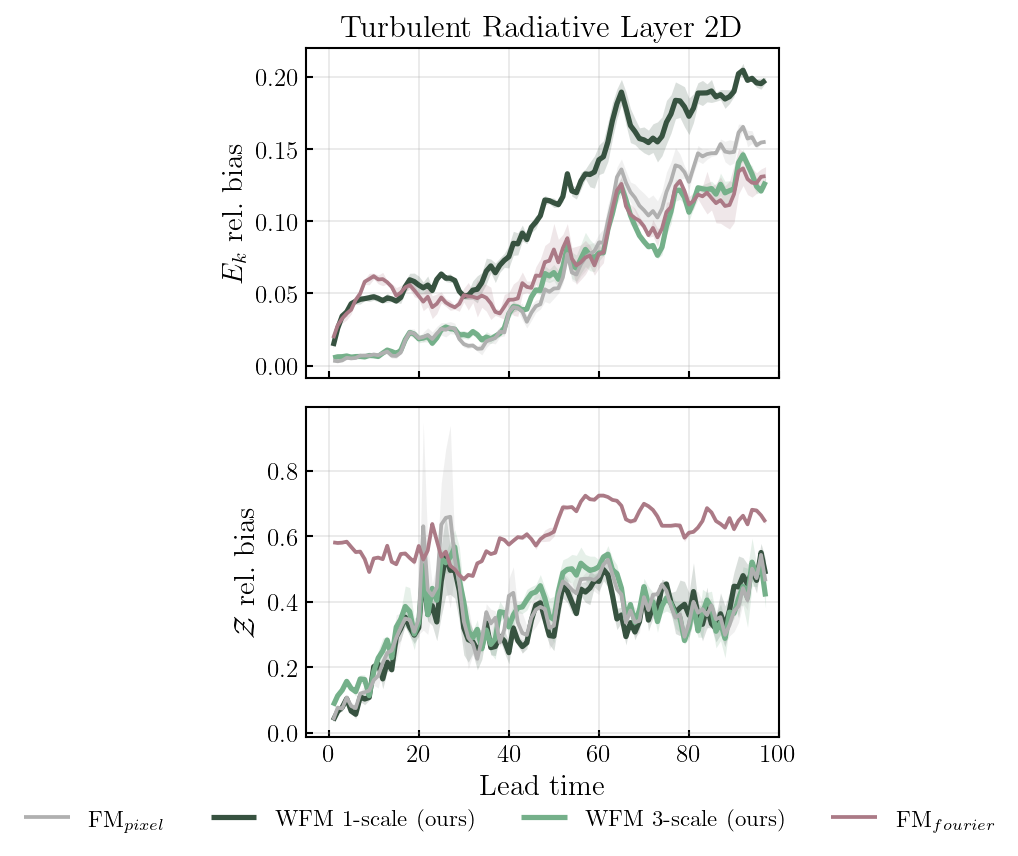

In [47]:
P1_ROWS = [
    ("ke_bias",          r"$E_k$ rel.\ bias",           dict(logy=False)),
    ("enstrophy_bias",   r"$\mathcal{Z}$ rel.\ bias",   dict(logy=False)),
    #("__conservation__", r"conservation ratio",         dict(logy=True, ref=1.0)),
]

n_pdes = max(len(pde_present), 1)
fig, axs = plt.subplots(
    len(P1_ROWS), n_pdes,
    figsize=(min(4.2 * n_pdes, TEXT_WIDTH), ROW_HEIGHT * len(P1_ROWS)),
    sharex="col", squeeze=False,
)

legend_models = []
for col, pde in enumerate(pde_present):
    ms = panel_models(pde)
    legend_models += ms
    for row, (metric, ylab, kw) in enumerate(P1_ROWS):
        ax  = axs[row][col]
        col_name = conservation_col(pde) if metric == "__conservation__" else metric
        if col_name is None or col_name not in g.columns:
            ax.set_visible(False); continue
        draw_metric(ax, g, pde, col_name, ms, mode="seed_avg", **kw)
        if col == 0:
            ax.set_ylabel(ylab, fontsize=14)
        if row == 0:
            ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")
        ax.set_xlabel("Lead time" if row == len(P1_ROWS) - 1 else "", fontsize=14)

add_legend(fig, legend_models, ncol=4, y=-0.03)
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(FIG_DIR / "figP1_physics_consistency.pdf",
                dpi=400, bbox_inches="tight", transparent=False)
plt.show()

# Figure P2 — energy budget tracking ($E_k$ pred vs.\ truth)

Absolute kinetic energy over the rollout: model curves (seed-averaged, main colors) against the ground-truth curve (black dashed). Decay below truth = artificial dissipation; growth above = energy injection.

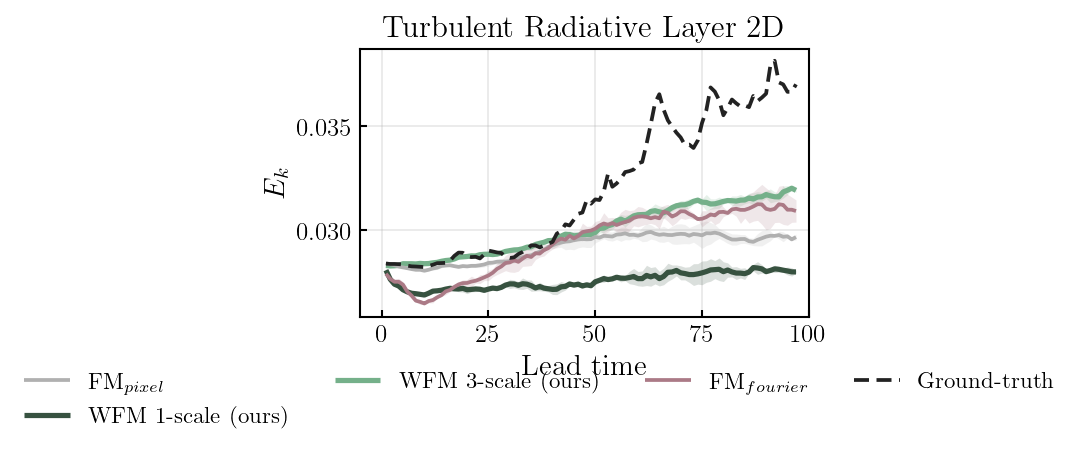

In [39]:
fig, axs = plt.subplots(1, n_pdes,
                        figsize=(min(4.2 * n_pdes, TEXT_WIDTH), ROW_HEIGHT),
                        squeeze=False)
legend_models = []
for col, pde in enumerate(pde_present):
    ax = axs[0][col]
    ms = panel_models(pde)
    legend_models += ms
    draw_metric(ax, g, pde, "ke_pred", ms, mode="seed_avg")
    # ground truth: identical across models/seeds — take the first available
    sub = g[(g["pde"] == pde)].dropna(subset=["ke_true"])
    if not sub.empty:
        m0  = sub["model"].iloc[0]; s0 = sub[sub["model"] == m0]["seed"].iloc[0]
        gt  = (sub[(sub["model"] == m0) & (sub["seed"] == s0)]
               .groupby("step")["ke_true"].mean())
        ax.plot(gt.index, gt.values, color=palette[GT_LABEL],
                dashes=dashes[GT_LABEL], lw=linewidths[GT_LABEL], zorder=4)
    ax.set_ylabel(r"$E_k$" if col == 0 else "", fontsize=14)
    ax.set_xlabel("Lead time", fontsize=14)
    ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

gt_handle = Line2D([], [], color=palette[GT_LABEL], dashes=dashes[GT_LABEL],
                   lw=linewidths[GT_LABEL])
add_legend(fig, legend_models, ncol=4, y=-0.10, extra=[(gt_handle, GT_LABEL)])
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(FIG_DIR / "figP2_energy_tracking.pdf",
                dpi=400, bbox_inches="tight", transparent=False)
plt.show()

# Figure P3 — attractor diagnostic: bias vs.\ MAE

Color = model, linestyle = statistic (solid MAE, dashed bias). Healthy: solid grows (chaotic decorrelation) while dashed stays flat (no systematic drift). Both growing = leaving the attractor.

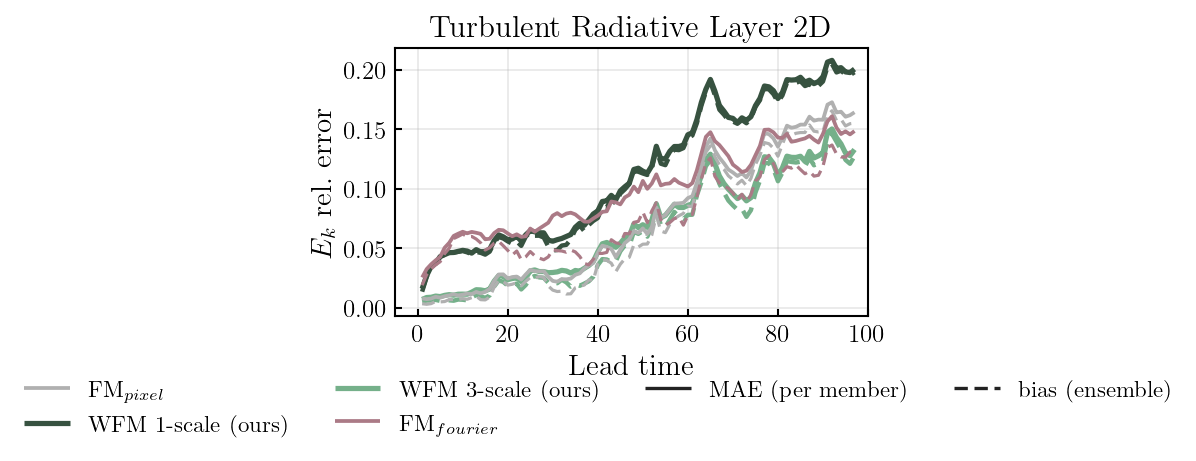

In [40]:
P3_METRIC = "ke"          # switch to "enstrophy" for the small-scale version

fig, axs = plt.subplots(1, n_pdes,
                        figsize=(min(4.2 * n_pdes, TEXT_WIDTH), ROW_HEIGHT),
                        squeeze=False)
legend_models = []
for col, pde in enumerate(pde_present):
    ax = axs[0][col]
    ms = panel_models(pde)
    legend_models += ms
    for m in ms:
        for stat, dash in ((f"{P3_METRIC}_mae", (1, 0)), (f"{P3_METRIC}_bias", (4, 2))):
            if stat not in g.columns:
                continue
            sc  = seed_mean(g[(g["pde"] == pde) & (g["model"] == m)], stat)
            if sc.empty:
                continue
            agg = sc.groupby("step")[stat].mean()
            ax.plot(agg.index, agg.values, color=palette[m], dashes=dash,
                    lw=linewidths[m] * (1.0 if dash == (1, 0) else 0.85))
    #ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.tick_params(direction="in", which="both", labelsize=12)
    ax.set_xlim(*pde_xlims.get(pde, (None, None)))
    ax.set_ylabel(rf"${P3_METRIC.replace('ke','E_k')}$ rel.\ error" if col == 0 else "",
                  fontsize=14)
    ax.set_xlabel("Lead time", fontsize=14)
    ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

extra = [(Line2D([], [], color="#222222", lw=1.6, dashes=(1, 0)), "MAE (per member)"),
         (Line2D([], [], color="#222222", lw=1.6, dashes=(4, 2)), "bias (ensemble)")]
add_legend(fig, legend_models, ncol=4, y=-0.12, extra=extra)
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(FIG_DIR / "figP3_bias_vs_mae.pdf",
                dpi=400, bbox_inches="tight", transparent=False)
plt.show()

# Figure P4 — seed-resolved curves

One line per (model, seed): shades of the model's registry color, darkest = lowest seed. Diagnostic view: near-coincident shades mean sampling stochasticity is small relative to model differences — itself a result.

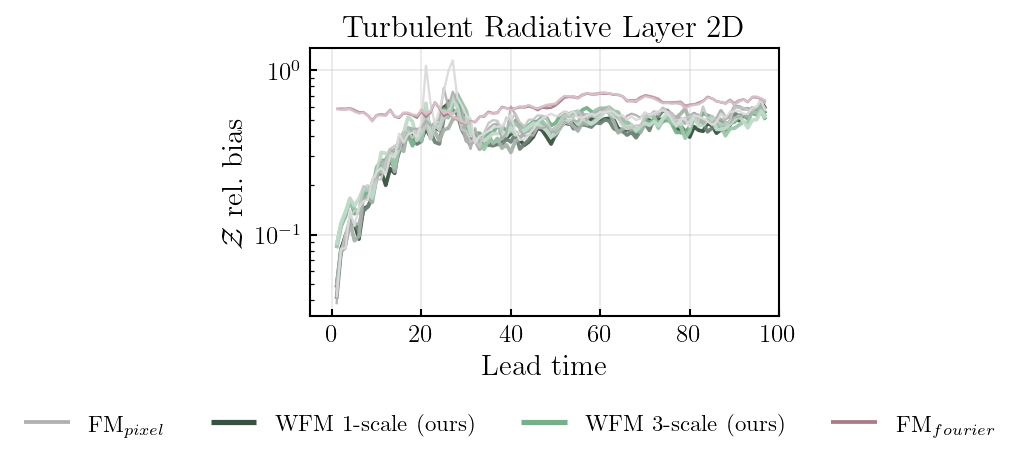

In [41]:
P4_METRIC = "enstrophy_mae"

fig, axs = plt.subplots(1, n_pdes,
                        figsize=(min(4.2 * n_pdes, TEXT_WIDTH), ROW_HEIGHT),
                        squeeze=False)
legend_models = []
for col, pde in enumerate(pde_present):
    ax = axs[0][col]
    ms = panel_models(pde)
    legend_models += ms
    draw_metric(ax, g, pde, P4_METRIC, ms, mode="per_seed", logy=True)
    ax.set_ylabel(r"$\mathcal{Z}$ rel.\ bias" if col == 0 else "", fontsize=14)
    ax.set_xlabel("Lead time", fontsize=14)
    ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

add_legend(fig, legend_models, ncol=4, y=-0.12)
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(FIG_DIR / "figP4_seed_resolved.pdf",
                dpi=400, bbox_inches="tight", transparent=False)
plt.show()

# Figure P5 — system-specific observables

One panel per PDE, each showing *its* scientific observable (TRL: mass flux, RB: Nusselt, AM: nematic order). Seed-averaged.

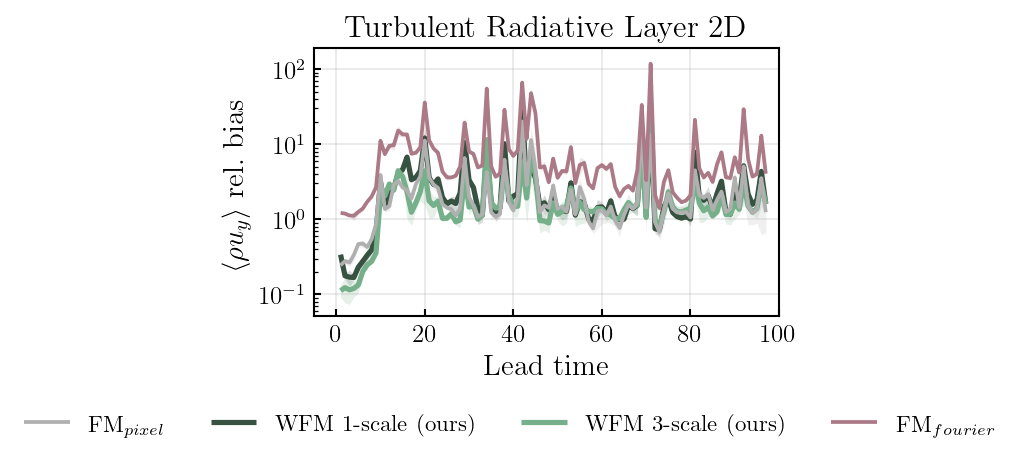

In [42]:
fig, axs = plt.subplots(1, n_pdes,
                        figsize=(min(4.2 * n_pdes, TEXT_WIDTH), ROW_HEIGHT),
                        squeeze=False)
legend_models = []
for col, pde in enumerate(pde_present):
    ax = axs[0][col]
    col_name, ylab = DATASET_METRIC.get(pde, (None, None))
    if col_name is None or col_name not in g.columns or g[g.pde == pde][col_name].isna().all():
        ax.set_visible(False); continue
    ms = panel_models(pde)
    legend_models += ms
    draw_metric(ax, g, pde, col_name, ms, mode="seed_avg", logy=True)
    ax.set_ylabel(ylab, fontsize=14)
    ax.set_xlabel("Lead time", fontsize=14)
    ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

add_legend(fig, legend_models, ncol=4, y=-0.12)
fig.tight_layout()
if SAVE_FIGS:
    fig.savefig(FIG_DIR / "figP5_dataset_observables.pdf",
                dpi=400, bbox_inches="tight", transparent=False)
plt.show()

# Figure P6 — per-field gradient energy \& positivity (one PDE)

Set `PDE_FOCUS`. Top row: $\langle|\nabla f|^2\rangle$ bias per channel; bottom: `neg_frac_pred` for the strictly positive channels.

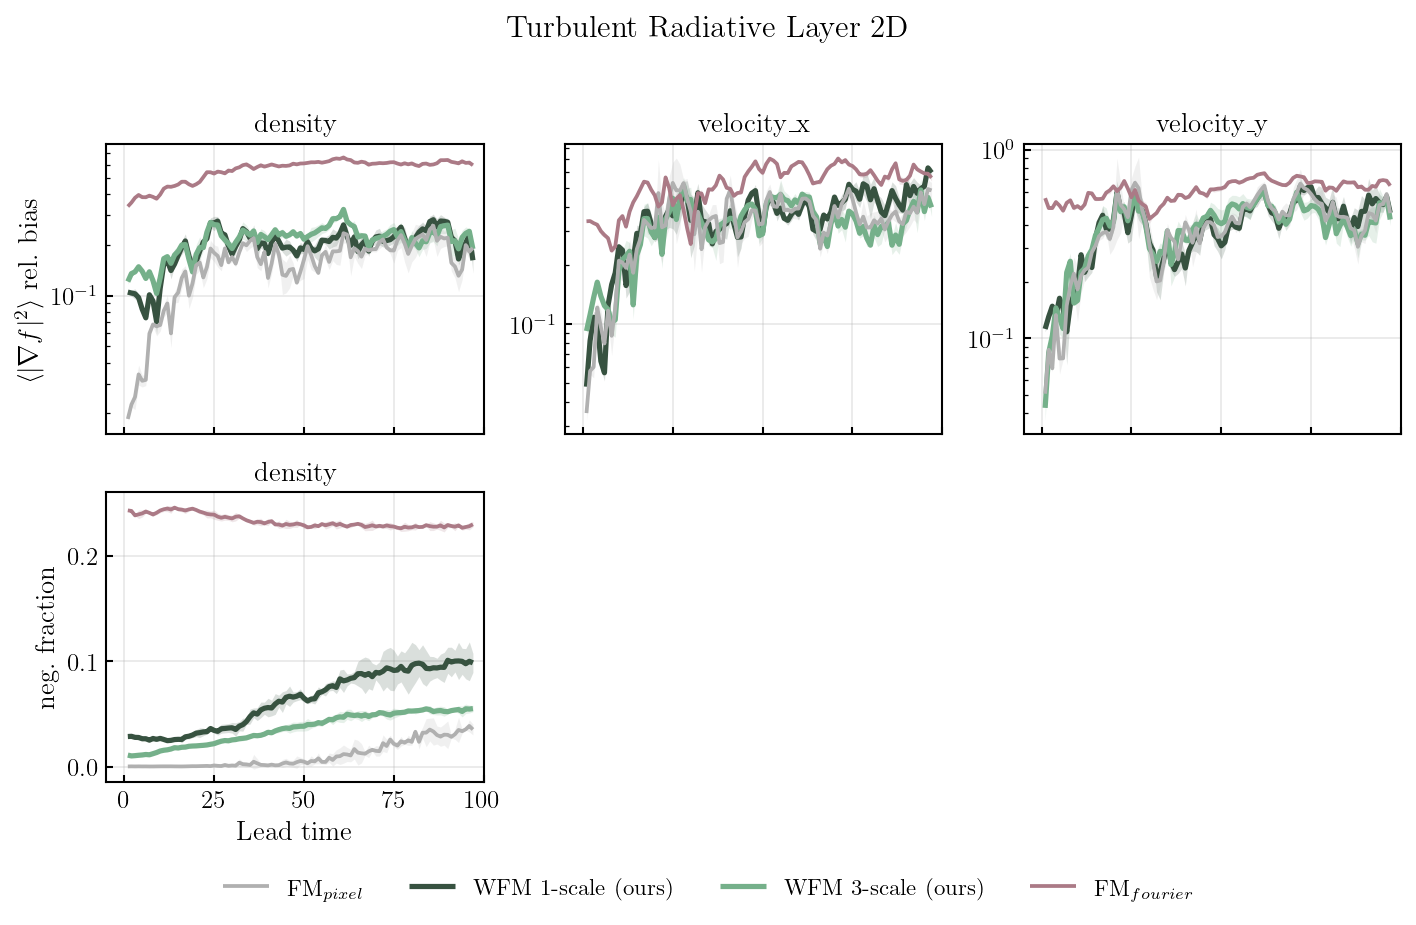

In [43]:
PDE_FOCUS = pde_present[0] if pde_present else None

if PDE_FOCUS is not None:
    sub_pf = pf[pf["pde"] == PDE_FOCUS]
    ms     = panel_models(PDE_FOCUS)

    gs_fields = sorted(sub_pf.dropna(subset=["gradsq_bias"])["field"].unique()) \
                if "gradsq_bias" in sub_pf.columns else []
    nf_fields = sorted(sub_pf.dropna(subset=["neg_frac_pred"])["field"].unique()) \
                if "neg_frac_pred" in sub_pf.columns else []

    ncols = max(len(gs_fields), len(nf_fields), 1)
    nrows = (1 if gs_fields else 0) + (1 if nf_fields else 0)
    if nrows:
        fig, axs = plt.subplots(nrows, ncols,
                                figsize=(min(3.2 * ncols, TEXT_WIDTH),
                                         ROW_HEIGHT * nrows),
                                squeeze=False, sharex=True)
        row = 0
        if gs_fields:
            for k, fld in enumerate(gs_fields):
                ax = axs[row][k]
                draw_metric(ax, sub_pf[sub_pf["field"] == fld], PDE_FOCUS,
                            "gradsq_bias", ms, mode="seed_avg", logy=True)
                ax.set_title(fld.replace("_", r"\_"), fontsize=13)
                if k == 0:
                    ax.set_ylabel(r"$\langle|\nabla f|^2\rangle$ rel.\ bias", fontsize=13)
            for k in range(len(gs_fields), ncols):
                axs[row][k].set_visible(False)
            row += 1
        if nf_fields:
            for k, fld in enumerate(nf_fields):
                ax = axs[row][k]
                draw_metric(ax, sub_pf[sub_pf["field"] == fld], PDE_FOCUS,
                            "neg_frac_pred", ms, mode="seed_avg", logy=False)
                ax.set_title(fld.replace("_", r"\_"), fontsize=13)
                ax.set_xlabel("Lead time", fontsize=13)
                if k == 0:
                    ax.set_ylabel(r"neg.\ fraction", fontsize=13)
            for k in range(len(nf_fields), ncols):
                axs[row][k].set_visible(False)

        fig.suptitle(PDE_LABELS.get(PDE_FOCUS, PDE_FOCUS), fontsize=15,
                     fontweight="bold", y=1.02)
        add_legend(fig, ms, ncol=4, y=-0.06)
        fig.tight_layout()
        if SAVE_FIGS:
            fig.savefig(FIG_DIR / f"figP6_perfield_{PDE_FOCUS}.pdf",
                        dpi=400, bbox_inches="tight", transparent=False)
        plt.show()

# Summary table — mean $\pm$ sd across seeds, per lead-time horizon

Aggregation order: mean over (traj, steps-in-horizon) **within** each seed → mean $\pm$ sd **across** seeds. Model separation larger than the sd rules out sampling luck; this is the table where late-horizon columns separate models after pointwise metrics have saturated.

In [44]:
SUMMARY_METRICS = ["ke_bias", "enstrophy_bias", "massflux_bias",
                   "nusselt_bias", "nematic_bias"] + CONS_CANDIDATES

PM_DISPLAY = "\u00b1"     # "±" for notebook display
PM_LATEX   = r"$\pm$"     # for .tex export only

def banded_summary(pde, pm=PM_DISPLAY):
    sub  = g[g["pde"] == pde]
    cols = [c for c in SUMMARY_METRICS if c in sub.columns and sub[c].notna().any()]
    out  = {}
    for c in cols:
        per_seed = (sub.dropna(subset=[c])
                    .groupby(["model", "seed", "horizon"])[c].mean())
        st = per_seed.groupby(["model", "horizon"]).agg(["mean", "std", "count"])
        out[c] = st.apply(
            lambda r: f"{r['mean']:.3f}" + (f" {pm} {r['std']:.3f}"
                                            if r["count"] > 1 else ""), axis=1)
    if not out:
        return None
    tab = pd.concat(out, axis=1).unstack("horizon")
    tab.index = [labels.get(m, m) for m in tab.index]
    return tab

for pde in pde_present:
    tab = banded_summary(pde)                    # display version: ±
    if tab is not None:
        print(f"\n===== {PDE_LABELS.get(pde, pde)} =====")
        try:
            from IPython.display import display
            display(tab)
        except Exception:
            print(tab.to_string())

# ── optional: LaTeX version for the paper ────────────────────────────────────
# tab_tex = banded_summary(pde_present[0], pm=PM_LATEX)
# print(tab_tex.to_latex(escape=False))          # escape=False keeps $\pm$ live


===== Turbulent Radiative Layer 2D =====


ke_bias                                \
horizon                          01:32          33:64          65:97   
FM$_{pixel}$             0.013 ± 0.001  0.050 ± 0.004  0.136 ± 0.006   
FM$_{fourier}$           0.047 ± 0.001  0.064 ± 0.006  0.115 ± 0.004   
WFM 1-scale haar (ours)  0.048 ± 0.001  0.103 ± 0.001  0.181 ± 0.006   
WFM 3-scale haar (ours)  0.014 ± 0.001  0.054 ± 0.003  0.114 ± 0.002   

                        enstrophy_bias                                \
horizon                          01:32          33:64          65:97   
FM$_{pixel}$             0.301 ± 0.042  0.389 ± 0.008  0.391 ± 0.005   
FM$_{fourier}$           0.541 ± 0.002  0.625 ± 0.004  0.652 ± 0.004   
WFM 1-scale haar (ours)  0.266 ± 0.016  0.355 ± 0.013  0.393 ± 0.029   
WFM 3-scale haar (ours)  0.306 ± 0.006  0.414 ± 0.028  0.388 ± 0.026   

                         massflux_bias                                 \
horizon                          01:32           33:64          65:97   
FM$_{pixel}$             2.184 ± 0.076   2.735 ± 0.311  2.570 ± 0.113   
FM$_{fourier}$           7.641 ± 0.257  11.440 ± 0.491  9.377 ± 0.160   
WFM 1-scale haar (ours)  2.797 ± 0.170   3.180 ± 0.229  2.707 ± 0.347   
WFM 3-scale haar (ours)  1.555 ± 0.223   2.202 ± 0.289  2.743 ± 0.367   

                        continuity_ratio                                
horizon                            01:32          33:64          65:97  
FM$_{pixel}$               1.004 ± 0.001  1.006 ± 0.001  1.005 ± 0.000  
FM$_{fourier}$             1.082 ± 0.000  1.094 ± 0.000  1.091 ± 0.002  
WFM 1-scale haar (ours)    1.002 ± 0.001  1.016 ± 0.001  1.017 ± 0.001  
WFM 3-scale haar (ours)    0.978 ± 0.002  0.970 ± 0.002  0.972 ± 0.001